# Characteristic scales over $(w_0, w_a)$

Braiding ($k_B$) and Jeans ($k_J$) scales today ($z=0$) for a fixed $(c_K, c_B)$, over a grid of
$(w_0, w_a)$ backgrounds. The scales are analytic; CLASS is only run (background only, a fraction of a
second each) to get $\Omega_{m,0}$ of each background with $\theta_s$ fixed.

In [1]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from hiclass_tools import Horndeski, backgrounds_from_class
from hiclass_tools.plotting import use_style

use_style(fontsize=12)

In [2]:
# Configuration
W0 = np.linspace(-1, -0.8, 25)
WA = np.linspace(-1, 0, 25)

CK = 1e4
CB = 1.0
PARAMETRIZATION = 'propto_omega'

WORKERS = None    # parallel CLASS runs (None: all cores)

In [3]:
# Omega_m0 of every background from CLASS (only w0 + wa <= 0)
pairs = [(w0, wa) for w0 in W0 for wa in WA if w0 + wa <= 0]
backgrounds = backgrounds_from_class(pairs, workers=WORKERS)

# Maps on the (wa, w0) grid: rows -> wa, columns -> w0. NaN where there is no valid background
kB_map = np.full((len(WA), len(W0)), np.nan)
kJ_map = np.full((len(WA), len(W0)), np.nan)
Om_map = np.full((len(WA), len(W0)), np.nan)

for (w0, wa), bg in backgrounds.items():
    i, j = np.where(WA == wa)[0][0], np.where(W0 == w0)[0][0]
    model = Horndeski(CK, CB, bg, PARAMETRIZATION)
    kB_map[i, j], kJ_map[i, j], Om_map[i, j] = model.kB(), model.kJ(), bg.Omega_m0

print(f"{len(backgrounds)} / {len(pairs)} backgrounds computed")
print(f"kB in [{np.nanmin(kB_map):.4g}, {np.nanmax(kB_map):.4g}] h/Mpc")
print(f"kJ in [{np.nanmin(kJ_map):.4g}, {np.nanmax(kJ_map):.4g}] h/Mpc")
print(f"Omega_m0 in [{np.nanmin(Om_map):.4f}, {np.nanmax(Om_map):.4f}]")

625 / 625 backgrounds computed
kB in [0.04476, 0.04718] h/Mpc
kJ in [0.02339, 0.03322] h/Mpc
Omega_m0 in [0.2542, 0.3732]


Text(0.5, 0.98, 'Characteristic scales at $z=0$ for $c_K = 1e+04$, $c_B = 1$')

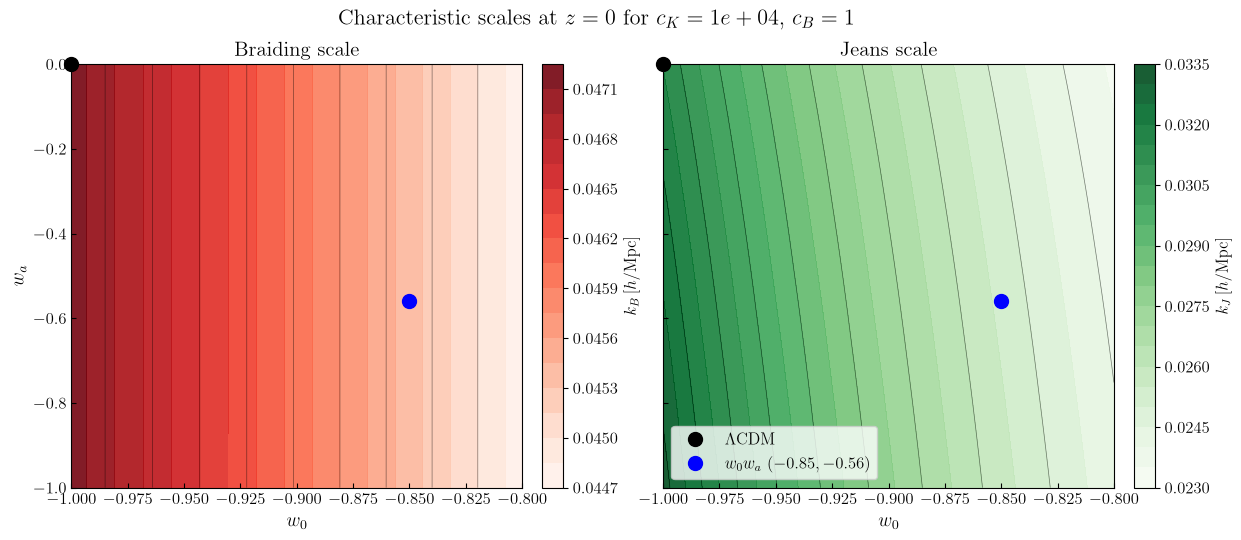

In [9]:
W0_grid, WA_grid = np.meshgrid(W0, WA)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

for ax, values, label, cmap in [(axs[0], kB_map, r'$k_B\,[h/\mathrm{Mpc}]$', 'Reds'),
                                (axs[1], kJ_map, r'$k_J\,[h/\mathrm{Mpc}]$', 'Greens')]:
    contour = ax.contourf(W0_grid, WA_grid, values, levels=20, cmap=cmap, alpha=0.9)
    ax.contour(W0_grid, WA_grid, values, levels=10, colors='k', linewidths=0.5, alpha=0.5)

    cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(label)

    # Reference backgrounds
    ax.plot(-1, 0, marker='o', color='k', markersize=10, linestyle='none', label=r'$\Lambda$CDM', clip_on=False, zorder=5)
    ax.plot(-0.85, -0.56, marker='o', color='b', markersize=10, linestyle='none', label=r'$w_0w_a$ $(-0.85, -0.56)$', clip_on=False, zorder=5)

    ax.set_xlabel(r'$w_0$', fontsize=14)
    ax.tick_params(axis='both', which='both', direction='in')

axs[0].set_ylabel(r'$w_a$', fontsize=14)
axs[0].set_title('Braiding scale', fontsize=15)
axs[1].set_title('Jeans scale', fontsize=15)
axs[1].legend(loc='lower left')

fig.suptitle(fr'Characteristic scales at $z=0$ for $c_K = {CK:.3g}$, $c_B = {CB:.3g}$', fontsize=16)